    
   ## **Satellite Image Comparison Project**

### Installing opencv-python for image pixel processing and tifffile for tiff image rgb pixels

In [99]:
%pip install opencv-python tifffile

Note: you may need to restart the kernel to use updated packages.


### Loading Images and Printing data shape and type 

In [100]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tifffile

img_2023 = tifffile.imread("Resource Images/2023-01-18_Bengaluru.tiff")
img_2026 = tifffile.imread("Resource Images/2026-01-22_Bengaluru.tiff")
img_before = tifffile.imread("Resource Images/NYC_2020.tiff")
img_after = tifffile.imread("Resource Images/NYC_2026.tiff")


print("2023 image shape:", img_2023.shape)
print("2024 image shape:", img_2026.shape)
print("2023 image dtype:", img_2023.dtype)
print("2024 image dtype:", img_2026.dtype)

2023 image shape: (215, 290, 3)
2024 image shape: (215, 290, 3)
2023 image dtype: uint8
2024 image dtype: uint8


### Comparing Images side by side (MatPlot.lib)

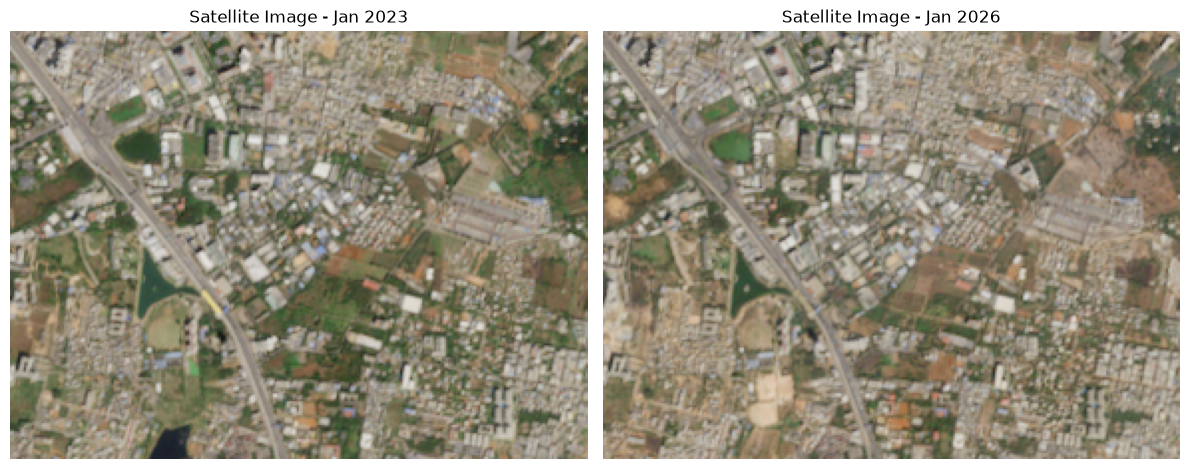

In [101]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_2023)
plt.title("Satellite Image - Jan 2023")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_2026)
plt.title("Satellite Image - Jan 2026")
plt.axis('off')

plt.tight_layout()
plt.show()

### Checking if dimensions of the images match 

In [102]:
print("2023 : ",(img_2023.shape))
print("2026 : ",(img_2026.shape))
assert img_2023.shape == img_2026.shape, "Image Dimensions do not match"
print("Image Dimensions match")

2023 :  (215, 290, 3)
2026 :  (215, 290, 3)
Image Dimensions match


### Converting Both images to same color format

In [103]:
print("2023 minimum and maximum:", img_2023.min(), img_2023.max())
print("2026 minimum and maximum:", img_2026.min(), img_2026.max())
print("2023 data type:", img_2023.dtype)
print("2026 data type:", img_2026.dtype)

2023 minimum and maximum: 6 230
2026 minimum and maximum: 10 228
2023 data type: uint8
2026 data type: uint8


### Converting Images to GreyScale and comparing side by side

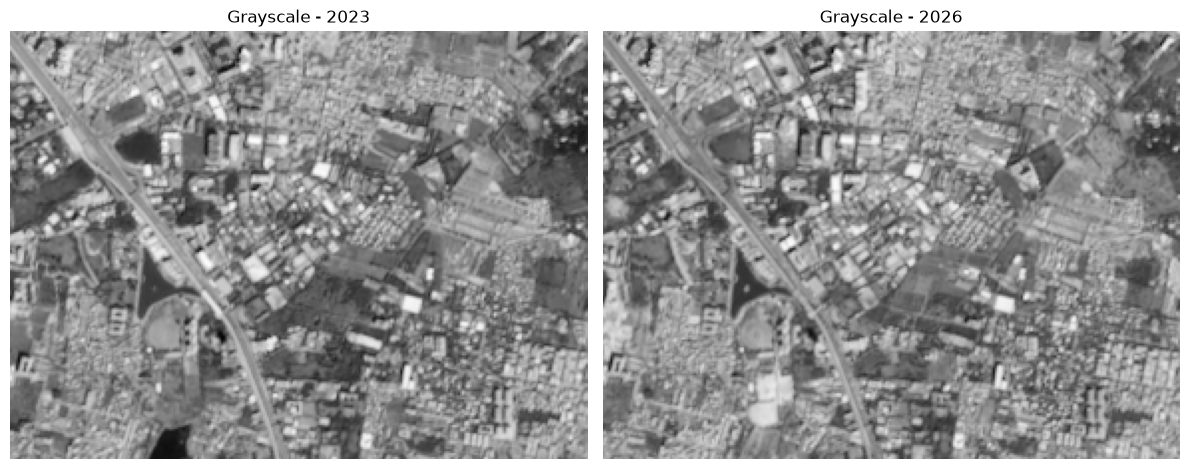

In [104]:
gray_2023 = cv2.cvtColor(img_2023, cv2.COLOR_RGB2GRAY)
gray_2026 = cv2.cvtColor(img_2026, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_2023, cmap="gray")
plt.title("Grayscale - 2023")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_2026, cmap="gray")
plt.title("Grayscale - 2026")
plt.axis("off")

plt.tight_layout()
plt.show()

### Calculate Absolute Difference between corresponding Pixels 

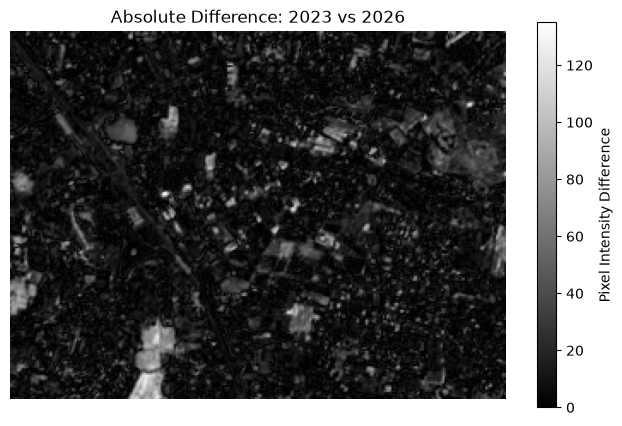

In [105]:
diff = cv2.absdiff(gray_2023, gray_2026)

plt.figure(figsize=(8, 5))
plt.imshow(diff, cmap="gray")
plt.title("Absolute Difference: 2023 vs 2026")
plt.axis("off")
plt.colorbar(label="Pixel Intensity Difference")
plt.show()

### Thresholding and Binary masking

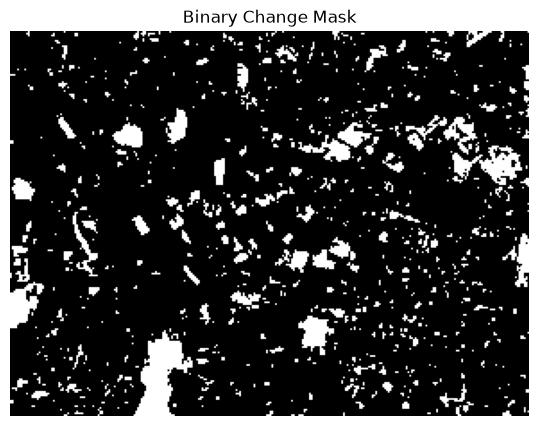

In [106]:
threshold_value = 30

_, change_mask = cv2.threshold(
    diff,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(8, 5))
plt.imshow(change_mask, cmap="gray")
plt.title("Binary Change Mask")
plt.axis("off")
plt.show()

### Applying Morphological Mask to remove noise 

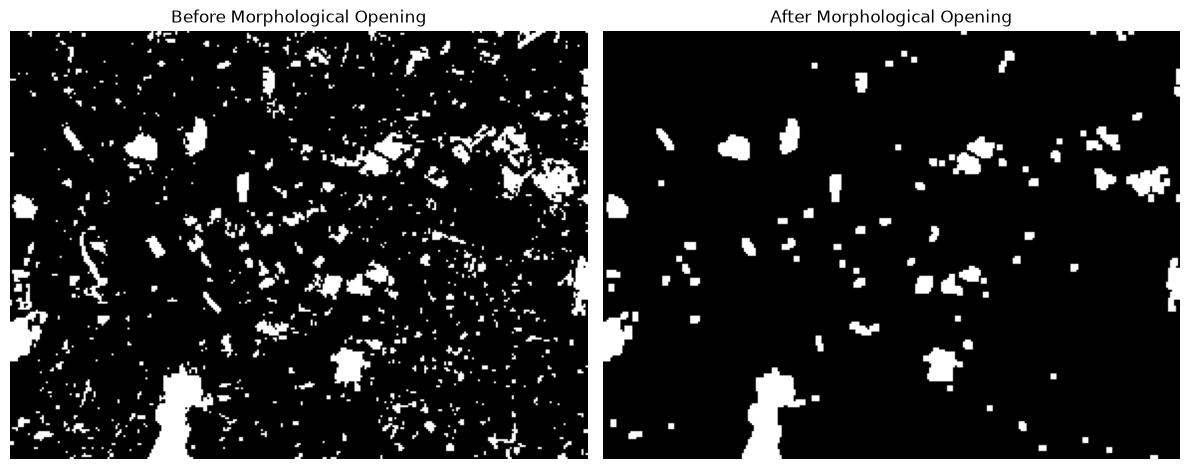

In [107]:
kernel = np.ones((3, 3), np.uint8)

cleaned_mask = cv2.morphologyEx(
    change_mask,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(change_mask, cmap="gray")
plt.title("Before Morphological Opening")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cleaned_mask, cmap="gray")
plt.title("After Morphological Opening")
plt.axis("off")

plt.tight_layout()
plt.show()

### Calculating Percentage Change 

In [108]:
changed_pixels = np.count_nonzero(cleaned_mask == 255)
total_pixels = cleaned_mask.size

change_percentage = (changed_pixels / total_pixels) * 100

print("Changed pixels after cleaning:", changed_pixels)
print("Total pixels:", total_pixels)
print(f"Detected change percentage: {change_percentage:.2f}%")

Changed pixels after cleaning: 3786
Total pixels: 62350
Detected change percentage: 6.07%


### Highlighting Detected Changes 

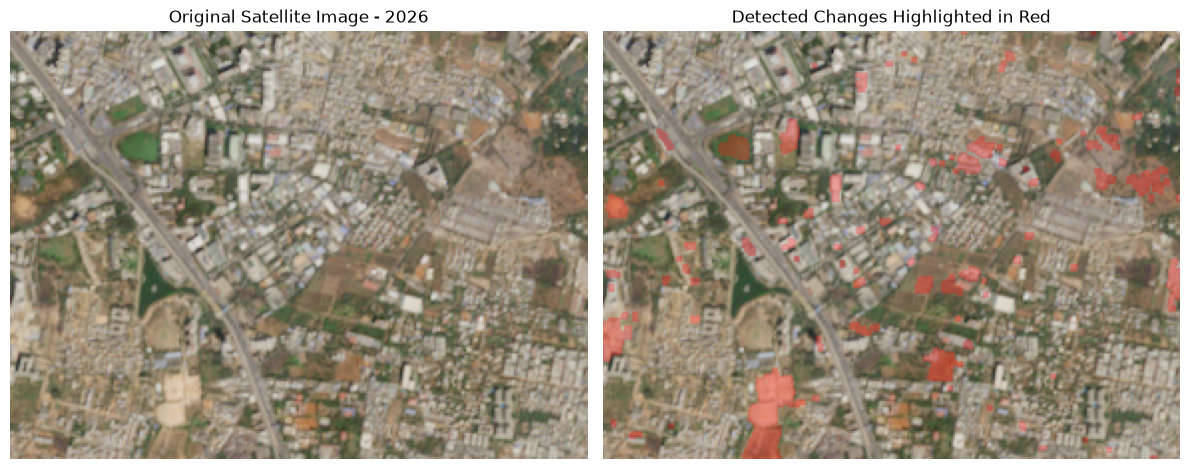

In [109]:
img_2026_rgb = cv2.cvtColor(img_2026, cv2.COLOR_BGR2RGB) if False else img_2026.copy()

highlighted = img_2026_rgb.copy()

highlighted[cleaned_mask == 255] = [255, 0, 0]

overlay = cv2.addWeighted(
    img_2026_rgb, 0.7,
    highlighted, 0.3,
    0
)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_2026_rgb)
plt.title("Original Satellite Image - 2026")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("Detected Changes Highlighted in Red")
plt.axis("off")

plt.tight_layout()
plt.show()

### Reducing False detection near Boundaries (Component Filtering)

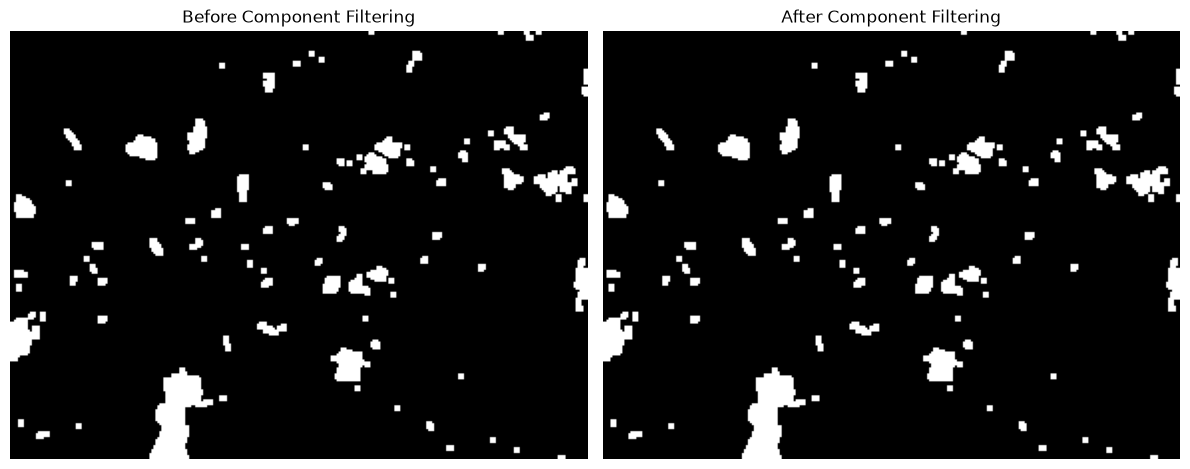

In [110]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    cleaned_mask,
    connectivity=8
)

min_area = 5

filtered_mask = np.zeros_like(cleaned_mask)

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= min_area:
        filtered_mask[labels == i] = 255

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cleaned_mask, cmap="gray")
plt.title("Before Component Filtering")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(filtered_mask, cmap="gray")
plt.title("After Component Filtering")
plt.axis("off")

plt.tight_layout()
plt.show()

### Recalculating Percentage Change 

In [111]:
changed_pixels = np.count_nonzero(filtered_mask == 255)
total_pixels = filtered_mask.size

change_percentage = (changed_pixels / total_pixels) * 100

print("Changed pixels:", changed_pixels)
print("Total pixels:", total_pixels)
print(f"Detected change percentage: {change_percentage:.2f}%")

Changed pixels: 3786
Total pixels: 62350
Detected change percentage: 6.07%


### Comparing for different Threshold values 

Threshold 15: 15.63%
Threshold 30: 6.07%
Threshold 50: 2.17%


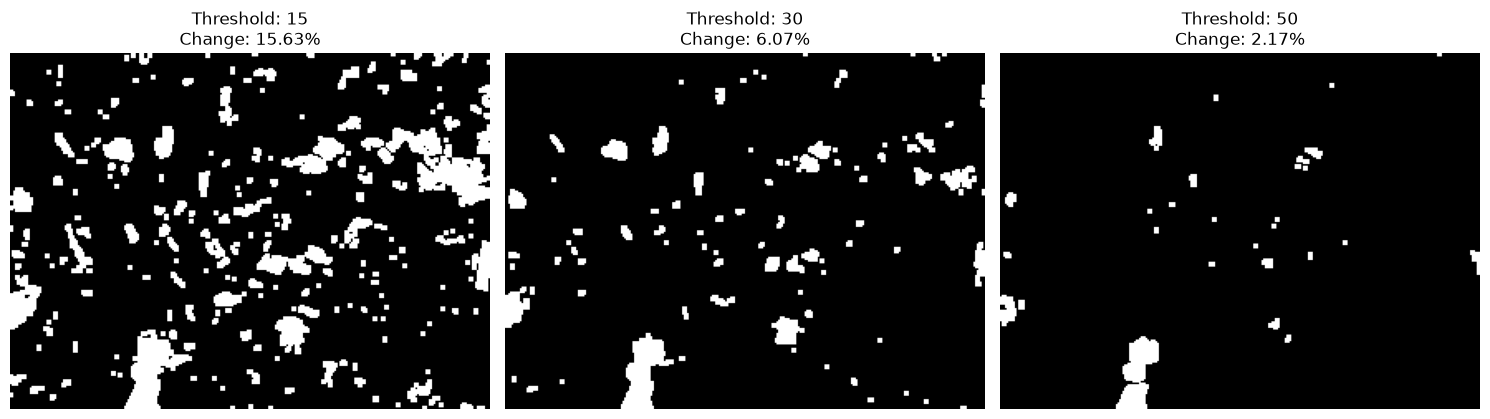

In [112]:
thresholds = [15, 30, 50]

plt.figure(figsize=(15, 5))

for i, value in enumerate(thresholds):
    _, mask = cv2.threshold(
        diff,
        value,
        255,
        cv2.THRESH_BINARY
    )

    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    percentage = np.count_nonzero(mask == 255) / mask.size * 100

    plt.subplot(1, 3, i + 1)
    plt.imshow(mask, cmap="gray")
    plt.title(f"Threshold: {value}\nChange: {percentage:.2f}%")
    plt.axis("off")

    print(f"Threshold {value}: {percentage:.2f}%")

plt.tight_layout()
plt.show()

### Final Comparison of Images (with Threshold of 30 pixels)

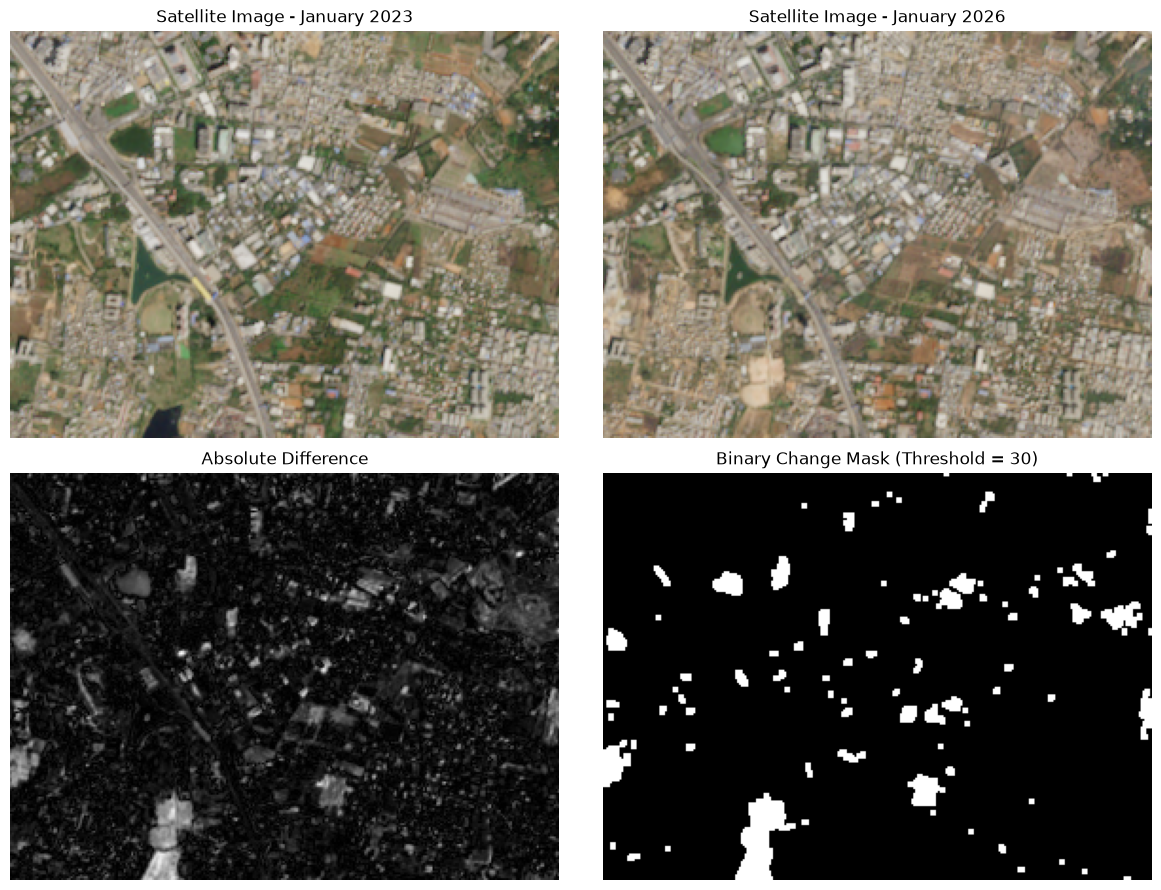

In [113]:
plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(img_2023)
plt.title("Satellite Image - January 2023")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(img_2026)
plt.title("Satellite Image - January 2026")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(diff, cmap="gray")
plt.title("Absolute Difference")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cleaned_mask, cmap="gray")
plt.title("Binary Change Mask (Threshold = 30)")
plt.axis("off")

plt.tight_layout()
plt.savefig("change_detection_results.png", dpi=300, bbox_inches="tight")
plt.show()

## Detected Area and Final Statistics 

In [114]:
total_pixels = cleaned_mask.size
changed_pixels = np.count_nonzero(cleaned_mask == 255)

change_percentage = (changed_pixels / total_pixels) * 100

pixel_area_m2 = 10 * 10
detected_area_m2 = changed_pixels * pixel_area_m2
detected_area_hectares = detected_area_m2 / 10000

print("Image dimensions:", cleaned_mask.shape)
print("Total pixels:", total_pixels)
print("Detected changed pixels:", changed_pixels)
print(f"Detected change ratio: {change_percentage:.2f}%")
print(f"Nominal detected area: {detected_area_m2:.0f} m²")
print(f"Nominal detected area: {detected_area_hectares:.2f} hectares")

Image dimensions: (215, 290)
Total pixels: 62350
Detected changed pixels: 3786
Detected change ratio: 6.07%
Nominal detected area: 378600 m²
Nominal detected area: 37.86 hectares


### Saving Final Binary Mask

In [115]:
cv2.imwrite("final_change_mask.png", cleaned_mask)
print("Final change mask saved.")

Final change mask saved.


### Checking Image Allignment before finalizing

2023 shape: (215, 290, 3)
2026 shape: (215, 290, 3)


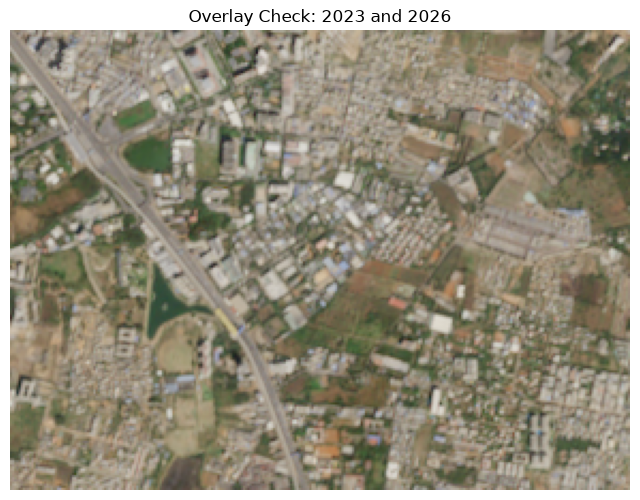

In [116]:
print("2023 shape:", img_2023.shape)
print("2026 shape:", img_2026.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img_2023)
plt.imshow(img_2026, alpha=0.5)
plt.title("Overlay Check: 2023 and 2026")
plt.axis("off")
plt.show()

### Result Image

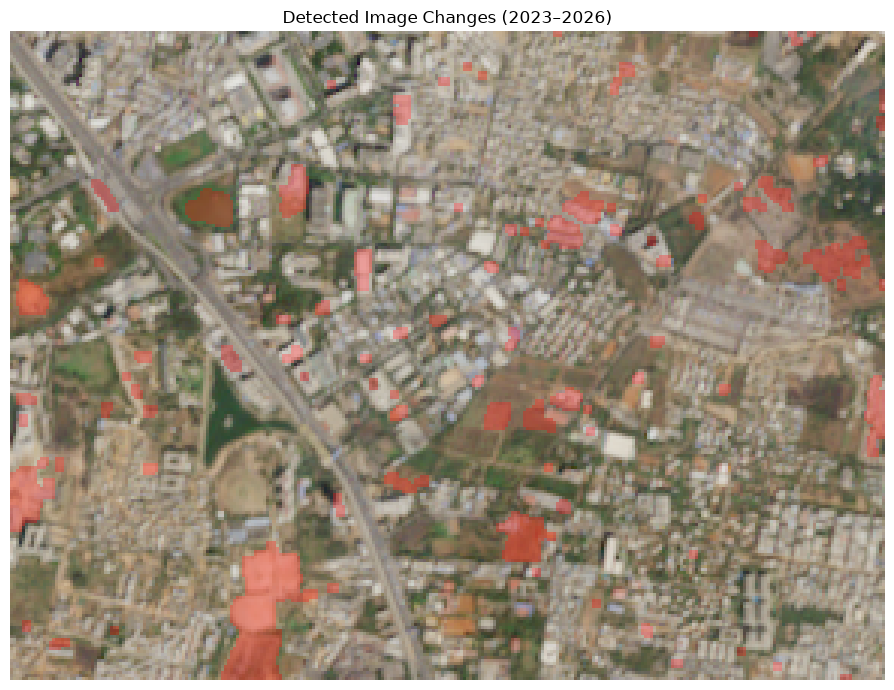

In [117]:
final_overlay = img_2026.copy()

final_overlay[cleaned_mask == 255] = [255, 0, 0]

final_overlay = cv2.addWeighted(
    img_2026, 0.7,
    final_overlay, 0.3,
    0
)

plt.figure(figsize=(10, 7))
plt.imshow(final_overlay)
plt.title("Detected Image Changes (2023–2026)")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    "final_change_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [118]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


### Result Table

In [119]:
import pandas as pd

results = pd.DataFrame({
    "Threshold": [15, 30, 50],
    "Detected Change (%)": [15.63, 6.07, 2.17]
})

print(results)

results.to_csv("threshold_comparison.csv", index=False)

   Threshold  Detected Change (%)
0         15                15.63
1         30                 6.07
2         50                 2.17


### checking output files

In [120]:
import os

files_to_check = [
    "change_detection_results.png",
    "final_change_mask.png",
    "final_change_overlay.png",
    "threshold_comparison.csv"
]

for filename in files_to_check:
    if os.path.exists(filename):
        print(filename, "- Saved successfully")
    else:
        print(filename, "- Not found")

change_detection_results.png - Saved successfully
final_change_mask.png - Saved successfully
final_change_overlay.png - Saved successfully
threshold_comparison.csv - Saved successfully


## *Generalized Satellite Image Testing with Pixel Comparison*

In [121]:

def detect_changes(image_before, image_after, threshold_value=30):
    if image_before.shape != image_after.shape:
        raise ValueError("Images must have matching dimensions and channels.")

    gray_before = cv2.cvtColor(image_before, cv2.COLOR_RGB2GRAY)
    gray_after = cv2.cvtColor(image_after, cv2.COLOR_RGB2GRAY)

    diff = cv2.absdiff(gray_before, gray_after)

    _, change_mask = cv2.threshold(
        diff, threshold_value, 255, cv2.THRESH_BINARY
    )

    kernel = np.ones((3, 3), np.uint8)

    cleaned_mask = cv2.morphologyEx(
        change_mask, cv2.MORPH_OPEN, kernel
    )

    change_percentage = (
        np.count_nonzero(cleaned_mask == 255) / cleaned_mask.size
    ) * 100

    highlighted = image_after.copy()
    highlighted[cleaned_mask == 255] = [255, 0, 0]

    overlay = cv2.addWeighted(
        image_after, 0.7, highlighted, 0.3, 0
    )

    return diff, cleaned_mask, overlay, change_percentage


In [122]:
diff_nyc, mask_nyc, overlay_nyc, percentage_nyc = detect_changes(
    img_before, img_after, threshold_value=30
)

print(f"NYC detected pixel-change ratio: {percentage_nyc:.2f}%")

NYC detected pixel-change ratio: 6.22%


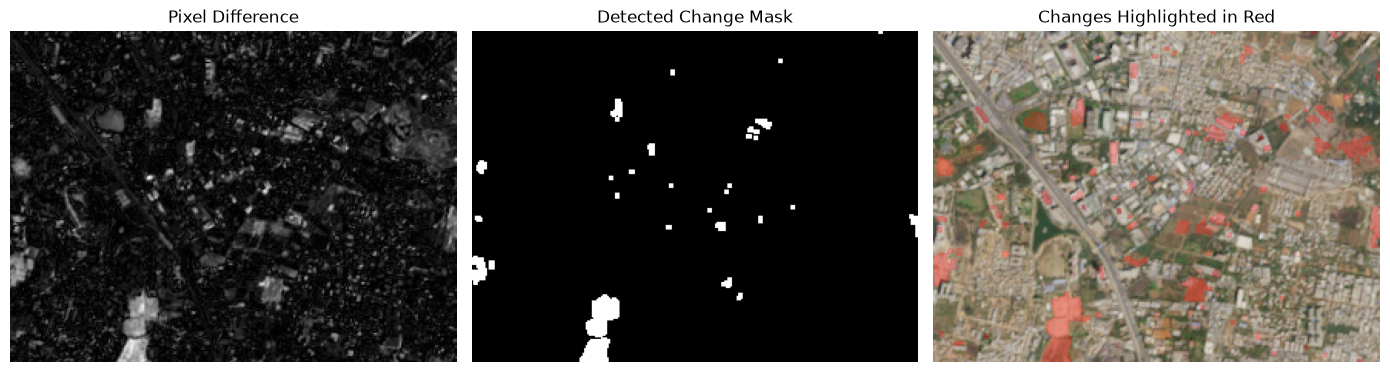

In [123]:

plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(diff, cmap="gray")
plt.title("Pixel Difference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Detected Change Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Changes Highlighted in Red")
plt.axis("off")

plt.tight_layout()
plt.show()


In [124]:
# Apply the same function to the NYC image pair
diff_nyc, mask_nyc, overlay_nyc, percentage_nyc = detect_changes(
    img_before, img_after, threshold_value=30
)

print("NYC image shapes:", img_before.shape, img_after.shape)
print(f"NYC detected pixel-change ratio (threshold 30): {percentage_nyc:.2f}%")

# Save NYC outputs separately so they do not overwrite Bengaluru results
cv2.imwrite("nyc_change_difference.png", diff_nyc)
cv2.imwrite("nyc_change_mask.png", mask_nyc)

# Matplotlib expects RGB channel order for display. This function assumes
# the input TIFFs are already RGB, matching the Bengaluru workflow.
plt.imsave("nyc_change_overlay.png", overlay_nyc)


NYC image shapes: (329, 612, 3) (329, 612, 3)
NYC detected pixel-change ratio (threshold 30): 6.22%


NYC threshold 15: 26.93%
NYC threshold 30: 6.22%
NYC threshold 50: 2.42%


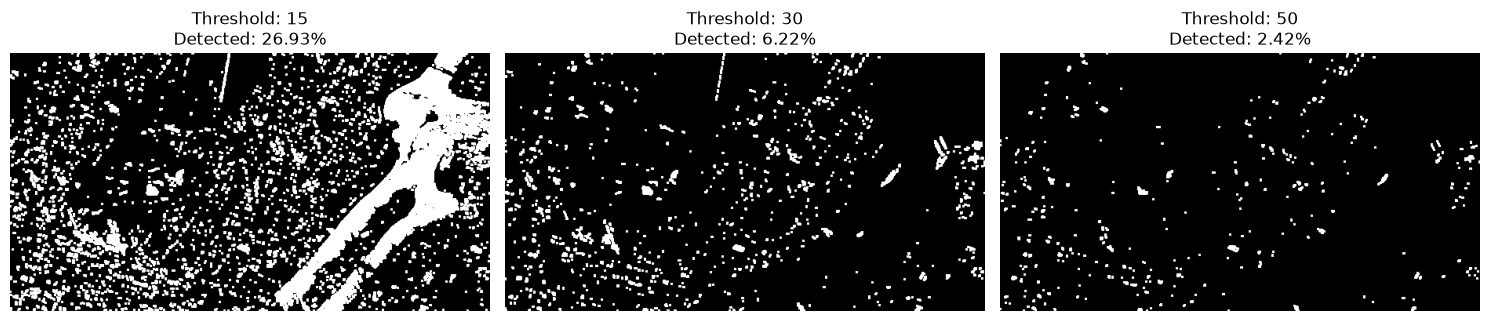

In [125]:
nyc_thresholds = [15, 30, 50]
nyc_threshold_results = []

plt.figure(figsize=(15, 5))

for i, value in enumerate(nyc_thresholds):
    _, nyc_threshold_mask = cv2.threshold(
        diff_nyc, value, 255, cv2.THRESH_BINARY
    )
    nyc_threshold_mask = cv2.morphologyEx(
        nyc_threshold_mask,
        cv2.MORPH_OPEN,
        np.ones((3, 3), np.uint8)
    )

    changed_pixels = np.count_nonzero(nyc_threshold_mask == 255)
    total_pixels = nyc_threshold_mask.size
    percentage = changed_pixels / total_pixels * 100
    nyc_threshold_results.append({
        "Threshold": value,
        "Changed Pixels": int(changed_pixels),
        "Total Pixels": int(total_pixels),
        "Detected Pixel-Change (%)": percentage
    })

    plt.subplot(1, 3, i + 1)
    plt.imshow(nyc_threshold_mask, cmap="gray")
    plt.title(f"Threshold: {value}\nDetected: {percentage:.2f}%")
    plt.axis("off")

    print(f"NYC threshold {value}: {percentage:.2f}%")

plt.tight_layout()
plt.show()

# Save NYC threshold results separately from Bengaluru's result table
import csv
with open("nyc_threshold_comparison.csv", "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=nyc_threshold_results[0].keys())
    writer.writeheader()
    writer.writerows(nyc_threshold_results)


In [126]:
import pandas as pd

nyc_results_df = pd.DataFrame(nyc_threshold_results)
display(nyc_results_df)

print("Baseline NYC result (threshold 30):")
print(f"Detected pixel-change ratio: {percentage_nyc:.2f}%")
print("Interpretation: this is a pixel-based difference ratio, not verified urban growth.")


,Threshold,Changed Pixels,Total Pixels,Detected Pixel-Change (%)
0,15,54227,201348,26.931978
1,30,12518,201348,6.217097
2,50,4881,201348,2.424161


Baseline NYC result (threshold 30):
Detected pixel-change ratio: 6.22%
Interpretation: this is a pixel-based difference ratio, not verified urban growth.
